<a href="https://colab.research.google.com/github/fatihibnisa/my-ml-projekt/blob/main/Kidney_Disease_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BUYRAK KASALLIKLARI UCHUN

In [53]:
import pandas as pd
import numpy as np


df = pd.read_csv('kidney_disease.csv')

In [54]:
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [55]:
df.columns

Index(['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr',
       'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad',
       'appet', 'pe', 'ane', 'classification'],
      dtype='object')

In [56]:
df.shape

(400, 26)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [58]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

# 1. Datasetni o'qish ('?' va boshqa noto'g'ri belgilar va bo'sh joylarni NaN ga o'tkazamiz)
df = pd.read_csv('kidney_disease.csv', na_values=['?', '\t?', '?', 'NaN', 'nan', ''])

# 2. Keraksiz 'id' ustunini o'chiramiz
if 'id' in df.columns:
    df.drop('id', axis=1, inplace=True)

# 3. Target ustunini ('classification') tozalash va standartlashtirish
# Har xil bo'sh joy yoki formatdagi yozuvlarni tozalaymiz
df['classification'] = df['classification'].astype(str).str.strip().str.lower()
df['classification'] = df['classification'].replace({'ckd': 1, 'notckd': 0, 'no': 0, 'ckd\t': 1})

# Agar target ustunida qiymat aniqlanmagan (NaN yoki noto'g'ri) qatorlar bo'lsa, ularni butunlay o'chirib tashlaymiz
df['classification'] = pd.to_numeric(df['classification'], errors='coerce')
df.dropna(subset=['classification'], inplace=True)
df['classification'] = df['classification'].astype(int)

# 4. Sonli va matnli ustunlardagi keraksiz bo'sh qatorlarni to'ldirish
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)
    # Matnli ustunlarni raqamlarga o'tkazamiz
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))

# 5. Tozalangan va faqat kerakli qatorlardan iborat datani saqlaymiz
df.to_csv('kidney_clean.csv', index=False)

print(f"Tozalash muvaffaqiyatli yakunlandi!")
print(f"Qolgan yaroqli qatorlar va ustunlar soni: {df.shape}")
print(f"Qolgan bo'sh qiymatlar soni: {df.isnull().sum().sum()}")

Tozalash muvaffaqiyatli yakunlandi!
Qolgan yaroqli qatorlar va ustunlar soni: (400, 25)
Qolgan bo'sh qiymatlar soni: 0


/tmp/ipykernel_3992/2957533740.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['classification'] = df['classification'].replace({'ckd': 1, 'notckd': 0, 'no': 0, 'ckd\t': 1})
/tmp/ipykernel_3992/2957533740.py:25: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), i

In [94]:
df.shape

(400, 25)

In [59]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,4,1,0,0,0,1
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.8,0,3,1,0,0,0,1
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.8,0,4,1,1,0,1,1
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,3,1,1,1,1,1
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,3,1,0,0,0,1


In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik stilini sozlaymiz
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

# Tozalangan datadan foydalanamiz
df_clean = pd.read_csv('kidney_clean.csv')

/tmp/ipykernel_3992/1359565644.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='classification', palette='Set2')


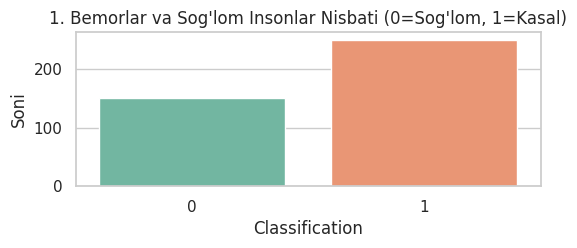

In [61]:
plt.figure(figsize=(6, 2))
sns.countplot(data=df_clean, x='classification', palette='Set2')
plt.title("1. Bemorlar va Sog'lom Insonlar Nisbati (0=Sog'lom, 1=Kasal)")
plt.xlabel("Classification")
plt.ylabel("Soni")
plt.show()

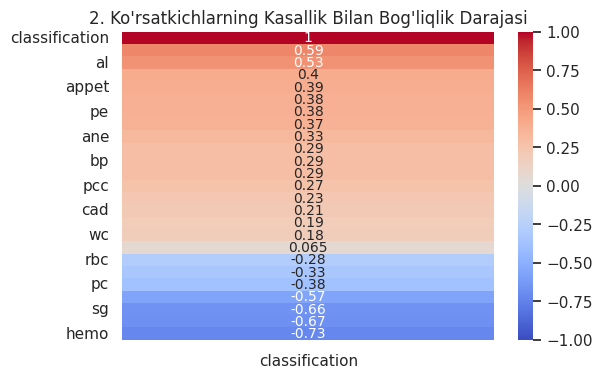

In [62]:
plt.figure(figsize=(6, 4))
sns.heatmap(df_clean.corr()[['classification']].sort_values(by='classification', ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("2. Ko'rsatkichlarning Kasallik Bilan Bog'liqlik Darajasi")
plt.show()

/tmp/ipykernel_3992/2347980318.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='classification', y='hemo', palette='Set2')


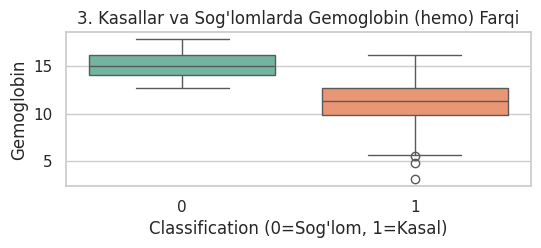

In [63]:
plt.figure(figsize=(6, 2))
sns.boxplot(data=df_clean, x='classification', y='hemo', palette='Set2')
plt.title("3. Kasallar va Sog'lomlarda Gemoglobin (hemo) Farqi")
plt.xlabel("Classification (0=Sog'lom, 1=Kasal)")
plt.ylabel("Gemoglobin")
plt.show()

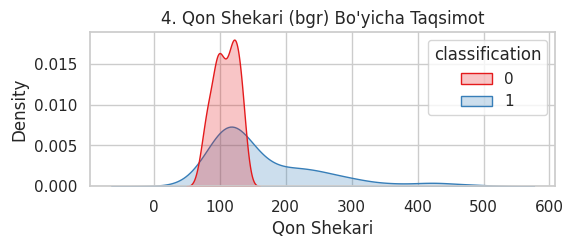

In [64]:
plt.figure(figsize=(6, 2))
sns.kdeplot(data=df_clean, x='bgr', hue='classification', common_norm=False, fill=True, palette='Set1')
plt.title("4. Qon Shekari (bgr) Bo'yicha Taqsimot")
plt.xlabel("Qon Shekari")
plt.show()

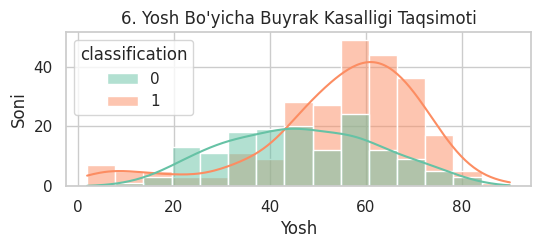

In [65]:
plt.figure(figsize=(6, 2))
sns.histplot(data=df_clean, x='age', hue='classification', kde=True, palette='Set2')
plt.title("6. Yosh Bo'yicha Buyrak Kasalligi Taqsimoti")
plt.xlabel("Yosh")
plt.ylabel("Soni")
plt.show()

/tmp/ipykernel_3992/3032989429.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='classification', y='sg', palette='coolwarm')


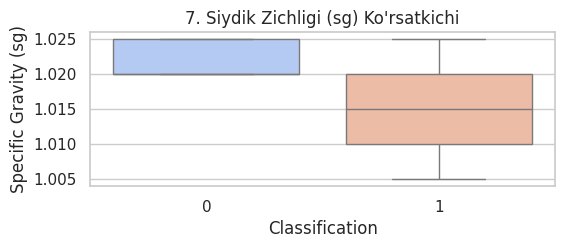

In [66]:
plt.figure(figsize=(6, 2))
sns.boxplot(data=df_clean, x='classification', y='sg', palette='coolwarm')
plt.title("7. Siydik Zichligi (sg) Ko'rsatkichi")
plt.xlabel("Classification")
plt.ylabel("Specific Gravity (sg)")
plt.show()

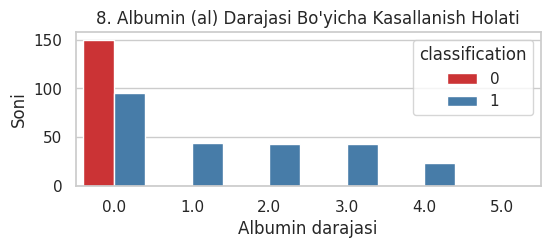

In [67]:
plt.figure(figsize=(6, 2))
sns.countplot(data=df_clean, x='al', hue='classification', palette='Set1')
plt.title("8. Albumin (al) Darajasi Bo'yicha Kasallanish Holati")
plt.xlabel("Albumin darajasi")
plt.ylabel("Soni")
plt.show()

/tmp/ipykernel_3992/812144043.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='classification', y='sc', palette='Set2')


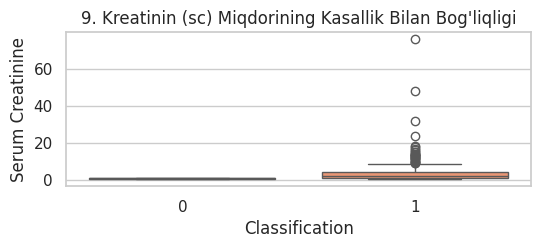

In [68]:
plt.figure(figsize=(6, 2))
sns.boxplot(data=df_clean, x='classification', y='sc', palette='Set2')
plt.title("9. Kreatinin (sc) Miqdorining Kasallik Bilan Bog'liqligi")
plt.xlabel("Classification")
plt.ylabel("Serum Creatinine")
plt.show()

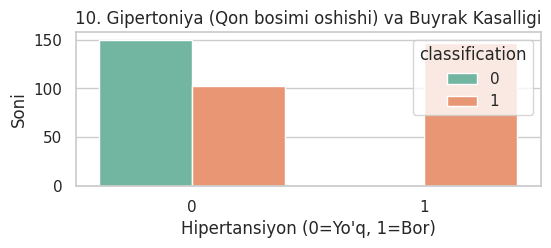

In [69]:
plt.figure(figsize=(6, 2))
sns.countplot(data=df_clean, x='htn', hue='classification', palette='Set2')
plt.title("10. Gipertoniya (Qon bosimi oshishi) va Buyrak Kasalligi")
plt.xlabel("Hipertansiyon (0=Yo'q, 1=Bor)")
plt.ylabel("Soni")
plt.show()

In [82]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [83]:
df = pd.read_csv('kidney_clean.csv')

# 2. Faqat eng muhim ustunlar va target'ni tanlab olamiz
selected_features = ['hemo', 'sc', 'pcv', 'sg', 'rc', 'htn', 'al', 'classification']

In [84]:
existing_features = [col for col in selected_features if col in df.columns]
df_filtered = df[existing_features]

In [85]:
X = df_filtered.drop('classification', axis=1)
y = df_filtered['classification']

In [87]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [88]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

In [89]:
xgb_model = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42)

In [90]:
rf_model.fit(X_train, y_train)


RandomForestClassifier(max_depth=5, random_state=42)

In [91]:

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [92]:
rf_pred = rf_model.predict(X_test)
xgb_pred = xgb_model.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)
xgb_acc = accuracy_score(y_test, xgb_pred)

print(f"--- Model Natijalari ---")
print(f"Random Forest Aniqligi (Accuracy): {rf_acc * 100:.2f}%")
print(f"XGBoost Aniqligi (Accuracy): {xgb_acc * 100:.2f}%\n")

--- Model Natijalari ---
Random Forest Aniqligi (Accuracy): 100.00%
XGBoost Aniqligi (Accuracy): 98.75%



Random Forest Train aniqligi: 98.75%
Random Forest Test aniqligi: 100.00%

Batafsil Hisobot (Random Forest uchun):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        28
           1       1.00      1.00      1.00        52

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



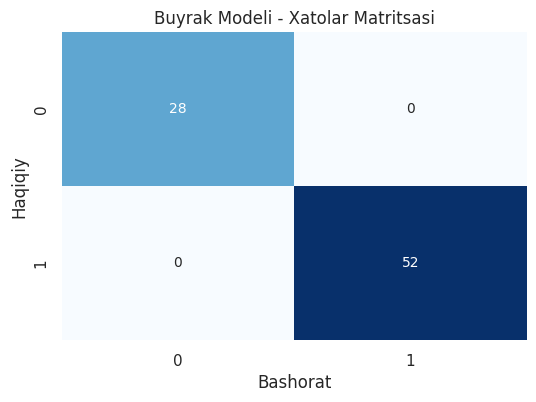

In [93]:
print(f"Random Forest Train aniqligi: {accuracy_score(y_train, rf_model.predict(X_train)) * 100:.2f}%")
print(f"Random Forest Test aniqligi: {rf_acc * 100:.2f}%\n")

# 6. Batafsil hisobot va Confusion Matrix
print("Batafsil Hisobot (Random Forest uchun):")
print(classification_report(y_test, rf_pred))

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Buyrak Modeli - Xatolar Matritsasi")
plt.xlabel("Bashorat")
plt.ylabel("Haqiqiy")
plt.show()

In [81]:
feature_imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Eng kuchli ta'sir qilgan ustunlar:")
print(feature_imp.head(10))

Eng kuchli ta'sir qilgan ustunlar:
hemo    0.292410
sc      0.195081
pcv     0.195040
sg      0.123786
rc      0.084732
al      0.078489
htn     0.030461
dtype: float64
